In [7]:
library('tidymodels')
library('palmerpenguins')
library('vip')
library('rpart.plot')

theme_set(theme_gray(base_size = 16))

In [2]:
penguins2 = penguins |>
    drop_na()

penguins2 |> head()

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

## Use random forests to model `bill_length_mm`

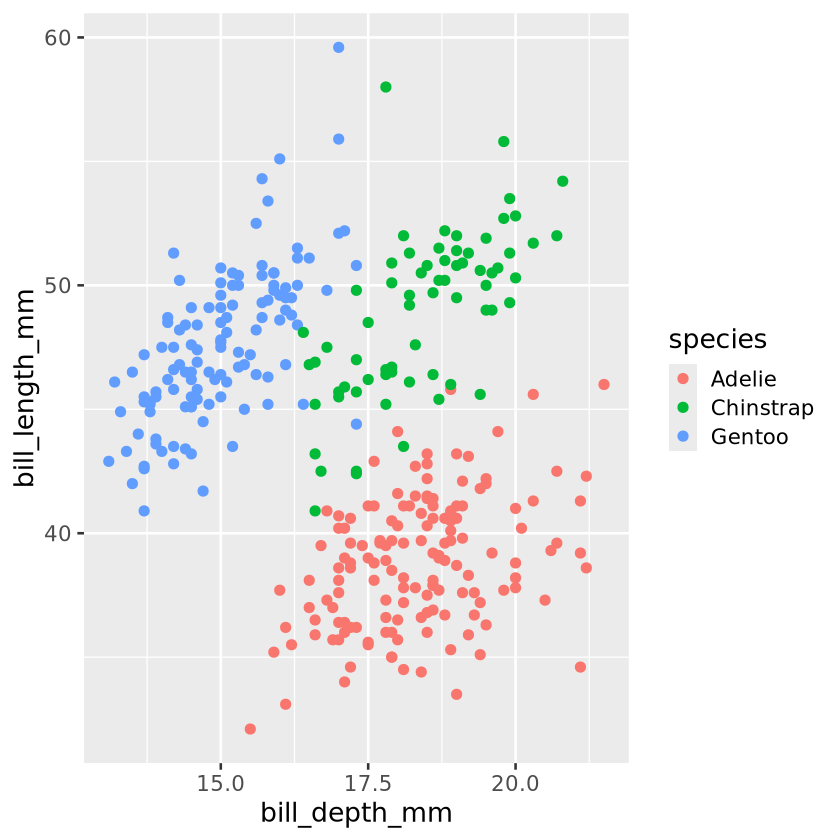

In [8]:
ggplot(penguins2, aes(y = bill_length_mm, x = bill_depth_mm, color = species)) + geom_point()

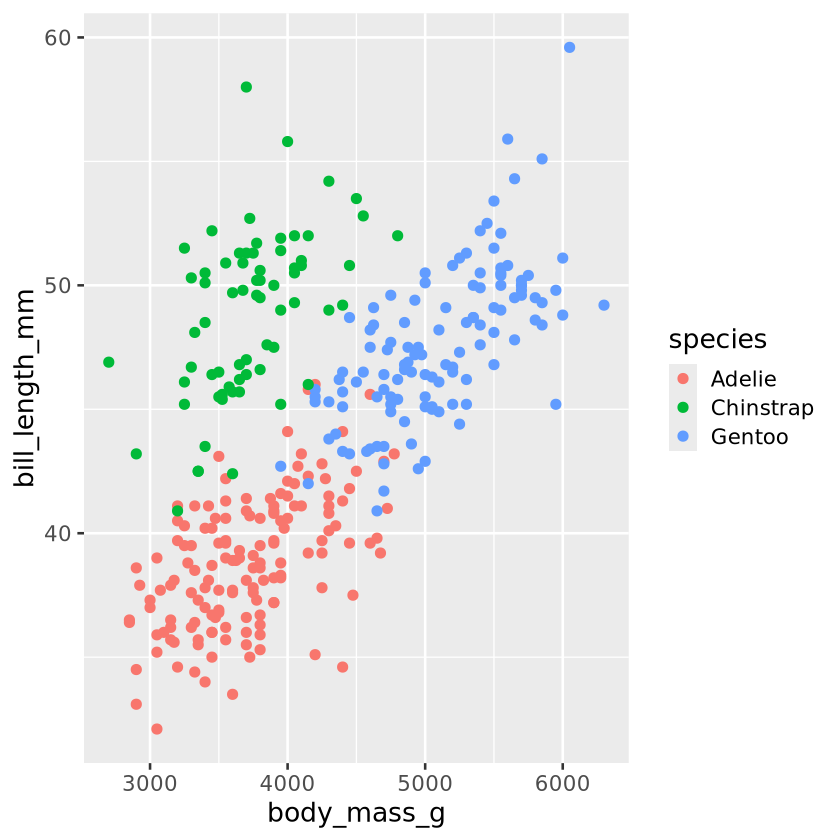

In [10]:
ggplot(penguins2, aes(y = bill_length_mm, x = body_mass_g, color = species)) + geom_point()

In [9]:
penguins2 |> names()

[1] "species"           "island"            "bill_length_mm"   
[4] "bill_depth_mm"     "flipper_length_mm" "body_mass_g"      
[7] "sex"               "year"             

In [35]:
mod = rand_forest() |> set_mode('regression')

mod

Random Forest Model Specification (regression)

Computational engine: ranger 


In [36]:
mod = rand_forest() |> 
    set_engine('ranger', importance = 'impurity') |>
    set_mode('regression')

In [37]:
mod_fit = mod |> fit(bill_length_mm ~ ., data = penguins2)

mod_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = "impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      333 
Number of independent variables:  7 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        variance 
OOB prediction error (MSE):       5.289669 
R squared (OOB):                  0.8231254 

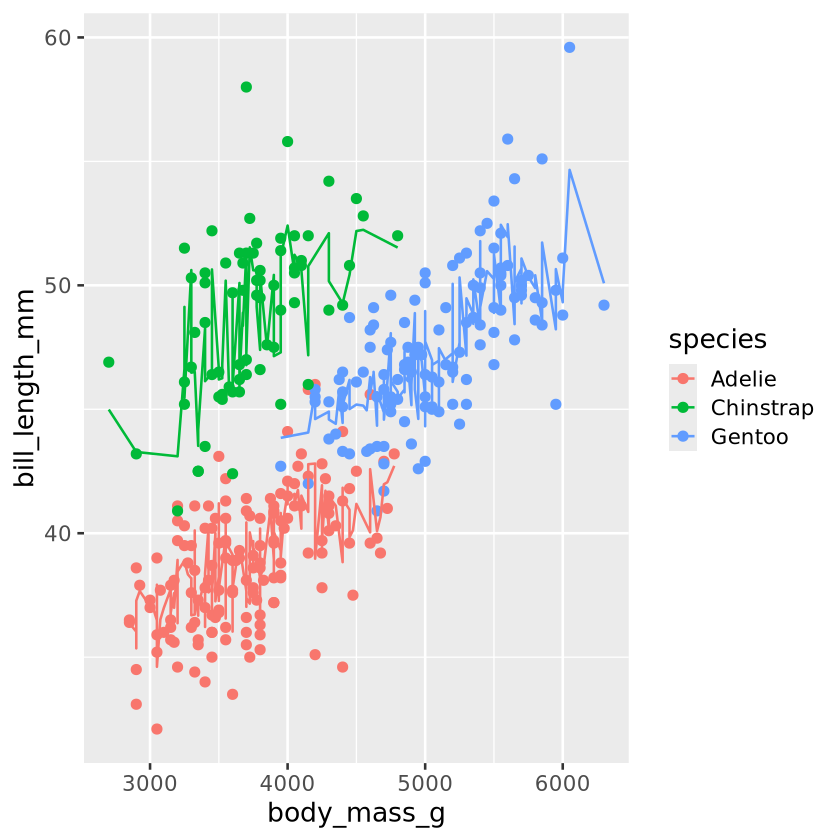

In [38]:
predict(mod_fit, new_data = penguins2) |> 
    bind_cols(penguins2) |> 
    ggplot(aes(y = bill_length_mm, x = body_mass_g, color = species)) + 
    geom_point() + 
    geom_line(aes(y = .pred))

In [39]:
rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species) |>
    prep(retain = TRUE)

rec |> juice() |> head()

  bill_depth_mm flipper_length_mm body_mass_g bill_length_mm sex_male
1 18.7          181               3750        39.1           1       
2 17.4          186               3800        39.5           0       
3 18.0          195               3250        40.3           0       
4 19.3          193               3450        36.7           0       
5 20.6          190               3650        39.3           1       
6 17.8          181               3625        38.9           0       
  island_Dream island_Torgersen species_Chinstrap species_Gentoo
1 0            1                0                 0             
2 0            1                0                 0             
3 0            1                0                 0             
4 0            1                0                 0             
5 0            1                0                 0             
6 0            1                0                 0             

In [40]:
wf = workflow() |> 
  add_recipe(rec) |> 
  add_model(mod)

wf_fit = wf |> fit(data = penguins2)

wf_fit

ERROR: 

In [41]:
outcomes = augment(wf_fit |> extract_fit_parsnip(), 
                   new_data = rec |> juice())

outcomes |> head()

ERROR: object 'wf_fit' not found

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 5)

ggplot(outcomes) +
    geom_point(aes(x = bill_depth_mm, y = bill_length_mm)) + 
    geom_point(aes(x = bill_depth_mm, y = .pred), color = 'steelblue', size = 3,
               alpha = 0.5) +
    geom_segment(aes(x = bill_depth_mm, xend = bill_depth_mm, y = .pred, yend = bill_length_mm), 
                 color = 'firebrick',
                 alpha = 0.25)

## Visualize feature importance

In [42]:
options(repr.plot.width = 6, repr.plot.height = 4)

wf_fit |> 
  extract_fit_parsnip() |> 
  vip()

ERROR: object 'wf_fit' not found

## Single decision tree

A single decision tree is a simpler, more interpretable alternative to a random forest.

In [43]:
tree_mod = decision_tree() |>
    set_engine('rpart') |>
    set_mode('regression')

tree_mod

Decision Tree Model Specification (regression)

Computational engine: rpart 


In [31]:
tree_fit = tree_mod |> fit(bill_length_mm ~ ., data = penguins2)

tree_fit

parsnip model object

n= 333 

node), split, n, deviance, yval
      * denotes terminal node

 1) root 333 9928.9030 43.99279  
   2) species=Adelie 146 1027.9660 38.82397  
     4) sex=female 73  296.3784 37.25753 *
     5) sex=male 73  373.3433 40.39041 *
   3) species=Chinstrap,Gentoo 187 1954.8800 48.02834  
     6) sex=female 92  580.5943 45.93696 *
     7) sex=male 95  582.1962 50.05368  
      14) bill_depth_mm< 16.45 53  248.0483 49.09434 *
      15) bill_depth_mm>=16.45 42  223.8164 51.26429 *

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


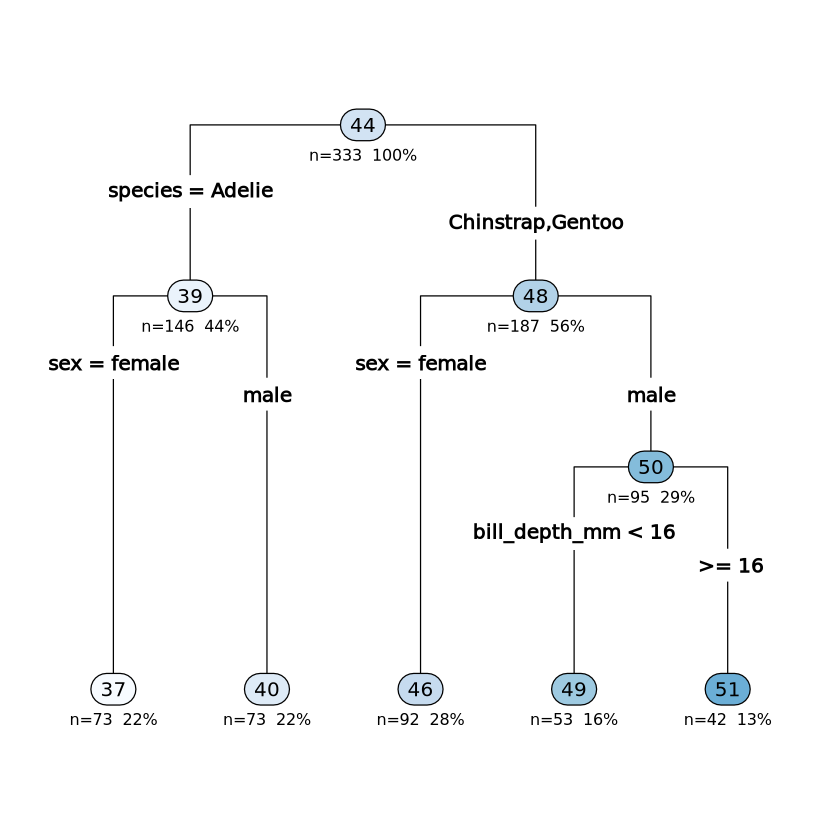

In [29]:
library('rpart.plot')

tree_fit |>
    extract_fit_engine() |>
    rpart.plot(type = 4, extra = 101, under = TRUE)

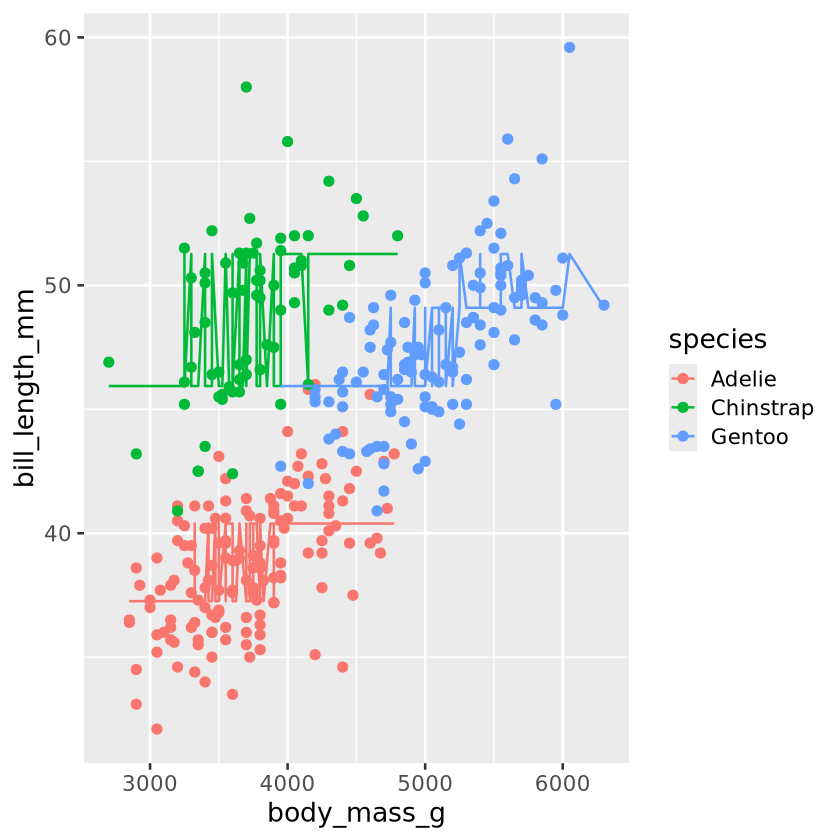

In [30]:
predict(tree_fit, new_data = penguins2) |>
    bind_cols(penguins2) |>
    ggplot(aes(y = bill_length_mm, x = body_mass_g, color = species)) +
    geom_point() +
    geom_line(aes(y = .pred))